# Taller 5: Diseño y Evaluación del Componente de Aprendizaje (Google Colab)
**Autor:** Alonso Toro | **Curso:** TEL-351 Agentes Inteligentes  
**Tema:** Dilema del Prisionero Iterado (IPD) — Preámbulo Taller IV (`Cloud`/`Rulito`), Agente Base MDP (`CDDC`) y RL *Online* con Olvido (`Mitcha`)

> **Notebook 100% autocontenido (`evolucion_agentes_taller5.ipynb`):** Este archivo único contiene **todo el código, las explicaciones de las Secciones 0 a 6, todas las tablas numéricas, los gráficos y las pruebas unitarias** del informe de 5 páginas. Puedes subir **exclusivamente este `.ipynb`** a Google Colab y presionar **`Entorno de ejecución -> Ejecutar todas` (`Runtime -> Run all`)**.

In [1]:
# Instalación automática en Google Colab (si la librería 'axelrod' no está instalada)
try:
    import axelrod as axl
except ImportError:
    import subprocess, sys
    print("Instalando librería axelrod en Google Colab...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "axelrod"])
    import axelrod as axl

from dataclasses import dataclass
import time
import unittest
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

t_nb_start = time.time()
print(f"Entorno listo | Axelrod v{axl.__version__} | NumPy v{np.__version__}")

Entorno listo | Axelrod v4.14.0 | NumPy v2.5.2


## 0. Preámbulo: Por qué se descartaron `Cloud` y `Rulito` del Taller IV

En el Taller IV se formularon dos prototipos sobre el MDP de memoria-1 ($\mathcal{S} = \{CC, CD, DC, DD\}$), descartados tras diagnosticar en el Torneo de Axelrod (1980, 10 semillas) tres fallas estructurales:
1. **Política miope (`CloudMiope`, Sección 7 del Taller IV, $\gamma = 0$):** Al estimar solo la probabilidad pasiva por estado $\hat{p}_s = \hat{P}(O_t = C \mid s_{t-1} = s)$ y maximizar el pago inmediato, se cumple $E[D] = 4\hat{p}_s + 1 > E[C] = 3\hat{p}_s$ para todo $\hat{p}_s \in [0, 1]$, obligando a traicionar siempre para $t > 10$ y colapsando al equilibrio de Nash $(D, D)$.
2. **Exploración forzada alternante ($C, D, C, D$ en $t \le 10$):** Al traicionar sin provocación en $t = 2$, activa el castigo perpetuo de rivales rencorosos como `Grudger` ($1.010$ pts/ronda).
3. **Transición no condicionada en $A_t$ (`RulitoBellman`, Sección 8 del Taller IV, $\gamma = 0.90$):** Al no separar $\hat{P}(O_t \mid s_{t-1}, A_t=C)$ de $\hat{P}(O_t \mid s_{t-1}, A_t=D)$, sobrecoopera ($97.5\%$) frente a estrategias ruidosas como `First by Joss`.

In [2]:
C = axl.Action.C
D = axl.Action.D

ACTION_D = 0
ACTION_C = 1
ACTIONS = (ACTION_D, ACTION_C)
ACTION_LABELS = {ACTION_D: "D", ACTION_C: "C"}

STATES = ("CC", "CD", "DC", "DD")
STATES_TUP = [(C, C), (C, D), (D, C), (D, D)]
STATE_MAP = {(C, C): 0, (C, D): 1, (D, C): 2, (D, D): 3}

PAYOFF = {
    (ACTION_C, ACTION_C): 3.0,
    (ACTION_C, ACTION_D): 0.0,
    (ACTION_D, ACTION_C): 5.0,
    (ACTION_D, ACTION_D): 1.0,
}
UNIFORM_PRIOR_P = {(s, a): 0.5 for s in range(4) for a in ACTIONS}


class CloudMiope(axl.Player):
    """Preámbulo Taller IV, Sección 7 ('Cloud', Miope gamma=0): exploración alternante t<=10 + conteo pasivo P(O_t=C | s_{t-1})."""
    name = "Cloud (Miope g=0)"

    def __init__(self, exploration_turns: int = 10, player_name: str = None):
        super().__init__()
        self.exploration_turns = int(exploration_turns)
        if player_name is not None:
            self.name = player_name
        self.reset_counts()

    def reset_counts(self) -> None:
        self.counts = {s: {C: 0, D: 0} for s in STATES_TUP}
        self.prev_state = None

    def reset(self) -> None:
        super().reset()
        self.reset_counts()

    def strategy(self, opponent: axl.Player) -> axl.Action:
        t = len(self.history)
        if t == 0:
            self.reset_counts()
            return C
        curr = (self.history[-1], opponent.history[-1])
        if self.prev_state is not None:
            self.counts[self.prev_state][opponent.history[-1]] += 1
        self.prev_state = curr
        if t < self.exploration_turns:
            return C if t % 2 == 0 else D
        tot = self.counts[curr][C] + self.counts[curr][D]
        p_c = (self.counts[curr][C] / tot) if tot > 0 else 0.5
        return C if (3.0 * p_c) >= (4.0 * p_c + 1.0) else D


class RulitoBellman(axl.Player):
    """Preámbulo Taller IV, Sección 8 ('Rulito', 1-Step gamma=0.90 no condicionado en A_t): P(O_t=C | s_{t-1})."""
    name = "Rulito (g=0.90)"

    def __init__(self, gamma: float = 0.90, exploration_turns: int = 10, player_name: str = None):
        super().__init__()
        self.gamma = float(gamma)
        self.exploration_turns = int(exploration_turns)
        if player_name is not None:
            self.name = player_name
        self.reset_counts()

    def reset_counts(self) -> None:
        self.counts = {s: {C: 0, D: 0} for s in STATES_TUP}
        self.prev_state = None

    def reset(self) -> None:
        super().reset()
        self.reset_counts()

    def _p_coop(self, s) -> float:
        tot = self.counts[s][C] + self.counts[s][D]
        return (self.counts[s][C] / tot) if tot > 0 else 0.5

    def strategy(self, opponent: axl.Player) -> axl.Action:
        t = len(self.history)
        if t == 0:
            self.reset_counts()
            return C
        curr = (self.history[-1], opponent.history[-1])
        if self.prev_state is not None:
            self.counts[self.prev_state][opponent.history[-1]] += 1
        self.prev_state = curr
        if t < self.exploration_turns:
            return C if t % 2 == 0 else D
        p_c = self._p_coop(curr)
        p_d = 1.0 - p_c
        v_next = {st: 4.0 * self._p_coop(st) + 1.0 for st in STATES_TUP}
        q_c = p_c * (3.0 + self.gamma * v_next[(C, C)]) + p_d * (0.0 + self.gamma * v_next[(C, D)])
        q_d = p_c * (5.0 + self.gamma * v_next[(D, C)]) + p_d * (1.0 + self.gamma * v_next[(D, D)])
        return C if q_c >= q_d else D


# Verificación rápida de las fallas de Cloud y Rulito vs Grudger y First by Joss
for lbl, ag in [("Cloud (Sec 7 T4, g=0)", CloudMiope()), ("Rulito (Sec 8 T4, g=0.90)", RulitoBellman())]:
    for opp_cls in [axl.Grudger, axl.FirstByJoss]:
        a, o = ag.clone(), opp_cls()
        axl.Match((a, o), turns=200, seed=42).play()
        pts = sum(PAYOFF[(ACTION_C if x==C else ACTION_D, ACTION_C if y==C else ACTION_D)] for x, y in zip(a.history, o.history)) / 200.0
        coop_pct = sum(1 for x in a.history if x == C) / 2.0
        print(f"{lbl:<26} vs {o.name:<15} -> {pts:.3f} pts/ronda (coop propia={coop_pct:.1f}%)")

Cloud (Sec 7 T4, g=0)      vs Grudger         -> 1.010 pts/ronda (coop propia=2.5%)
Cloud (Sec 7 T4, g=0)      vs First by Joss   -> 1.090 pts/ronda (coop propia=2.5%)
Rulito (Sec 8 T4, g=0.90)  vs Grudger         -> 1.010 pts/ronda (coop propia=2.5%)
Rulito (Sec 8 T4, g=0.90)  vs First by Joss   -> 2.660 pts/ronda (coop propia=97.5%)


## 1. ¿Cuál será el agente base? (Tabla de Frecuencias de 8 Contextos + Bellman -> `CDDC`)

Partiendo del MDP de memoria-1 ($\mathcal{S}=\{CC, CD, DC, DD\}$, $\mathcal{A}=\{C, D\}$), el **Agente Base sin aprendizaje en línea** (`EmpiricalPolicyAgent`) obtiene su política estacionaria fija $\pi_0$ *offline*:
- **Información que recibe y decisión:** en $t = 1$ ($S_0 = \text{Historial vacío}$) abre cooperando ($A_1 = C$, regla *Nice*); desde $t \ge 2$ observa $s_{t-1} = (A_{t-1}, O_{t-1})$ y ejecuta $A_t = \pi_0[s_{t-1}]$.
- **Matriz base $T_0$:** simula duelos todos contra todos entre $30$ estrategias de Axelrod (`build_training_pool`, $200$ rondas, $N = 173{,}130$ transiciones) y calcula por conteo supervisado exacto $\hat{p}_0(s, a) = \hat{P}(O_t = C \mid s_{t-1}=s, A_t=a) = K_{s,a} / N_{s,a}$, formando la matriz $T_0 \in [0, 1]^{8 \times 4}$.
- **Solución de Bellman (*Value Iteration*, $\gamma = 0.90$, tolerancia $\le 0.000001 = 10^{-6}$):**
  $$Q^*(s, a) = \hat{p}_0(s, a)\big[R(a, C) + \gamma V^*((a, C))\big] + \big(1 - \hat{p}_0(s, a)\big)\big[R(a, D) + \gamma V^*((a, D))\big], \qquad V^*(s) = \max_{a \in \{C, D\}} Q^*(s, a)$$
  de donde emerge la política base fija $\pi_0 = [C, D, D, C]$ (**`CDDC`**, Pavlov / WSLS) tras converger sin corte artificial en 141 barridos ($\max_s |V^{(k)}(s)-V^{(k-1)}(s)| \le 10^{-6}$).

In [3]:
@dataclass(frozen=True)
class FrequencyTableResult:
    counts_coop: dict
    counts_total: dict
    p_coop: dict
    mdp_transitions: dict
    total_transitions: int


@dataclass(frozen=True)
class BellmanResult:
    v_values: list
    q_values: dict
    delta_q: list
    policy: list
    iterations: int = 0


def build_training_pool() -> list:
    strategy_classes = [
        axl.Cooperator, axl.Defector, axl.TitForTat, axl.TitFor2Tats, axl.TwoTitsForTat,
        axl.Grudger, axl.WinStayLoseShift, axl.Alternator, axl.Random, axl.Bully,
        axl.GTFT, axl.HardTitForTat, axl.SuspiciousTitForTat, axl.ZDExtort2, axl.ZDGTFT2,
        axl.Adaptive, axl.Detective, axl.Appeaser, axl.CyclerCCD, axl.CyclerDDC,
        axl.Prober, axl.Prober2, axl.Gradual, axl.FoolMeOnce, axl.GoByMajority,
        axl.HardGoByMajority, axl.ContriteTitForTat, axl.SlowTitForTwoTats2, axl.BackStabber, axl.AverageCopier,
    ]
    return [cls() for cls in strategy_classes]


def _record_perspective(my_history, opp_history, counts_coop, counts_total) -> None:
    for t in range(1, len(my_history)):
        prev_state = STATE_MAP[(my_history[t - 1], opp_history[t - 1])]
        my_action = ACTION_C if my_history[t] == C else ACTION_D
        opp_coop = 1 if opp_history[t] == C else 0
        key = (prev_state, my_action)
        counts_total[key] += 1
        counts_coop[key] += opp_coop


def build_mdp_transition_matrix(p_coop: dict) -> dict:
    transitions = {}
    for s in range(4):
        for a in ACTIONS:
            p_c = p_coop[(s, a)]
            transitions[(s, a)] = {0: p_c, 1: 1.0 - p_c, 2: 0.0, 3: 0.0} if a == ACTION_C else {0: 0.0, 1: 0.0, 2: p_c, 3: 1.0 - p_c}
    return transitions


def collect_frequency_table(strategies: list, turns: int = 200, repetitions: int = 1, seed: int = 42) -> FrequencyTableResult:
    keys = [(s, a) for s in range(4) for a in ACTIONS]
    counts_coop = {k: 0 for k in keys}
    counts_total = {k: 0 for k in keys}
    num_players = len(strategies)
    match_seed = seed
    for _ in range(repetitions):
        for i in range(num_players):
            for j in range(i + 1, num_players):
                p1, p2 = strategies[i].clone(), strategies[j].clone()
                axl.Match((p1, p2), turns=turns, seed=match_seed).play()
                _record_perspective(p1.history, p2.history, counts_coop, counts_total)
                _record_perspective(p2.history, p1.history, counts_coop, counts_total)
                if match_seed is not None:
                    match_seed += 1
    p_coop = {k: (counts_coop[k] / counts_total[k]) if counts_total[k] > 0 else 0.5 for k in keys}
    return FrequencyTableResult(
        counts_coop=counts_coop,
        counts_total=counts_total,
        p_coop=p_coop,
        mdp_transitions=build_mdp_transition_matrix(p_coop),
        total_transitions=sum(counts_total.values()),
    )


def _compute_q_sa(v_values: list, p_coop: dict, state: int, action: int, gamma: float) -> float:
    p_c = p_coop[(state, action)]
    s_next_c = 0 if action == ACTION_C else 2
    s_next_d = 1 if action == ACTION_C else 3
    return p_c * (PAYOFF[(action, ACTION_C)] + gamma * v_values[s_next_c]) + (1.0 - p_c) * (PAYOFF[(action, ACTION_D)] + gamma * v_values[s_next_d])


def solve_bellman(p_coop: dict, gamma: float = 0.90, tol: float = 1e-6, max_iter: int = 2000) -> BellmanResult:
    """Resuelve Bellman por Value Iteration hasta que max_s |V^(k)(s) - V^(k-1)(s)| <= tol (0.000001)."""
    p0c, p0d = p_coop[(0, ACTION_C)], p_coop[(0, ACTION_D)]
    p1c, p1d = p_coop[(1, ACTION_C)], p_coop[(1, ACTION_D)]
    p2c, p2d = p_coop[(2, ACTION_C)], p_coop[(2, ACTION_D)]
    p3c, p3d = p_coop[(3, ACTION_C)], p_coop[(3, ACTION_D)]
    v0 = v1 = v2 = v3 = 0.0
    iters = 0
    for it in range(1, max_iter + 1):
        iters = it
        gv0, gv1, gv2, gv3 = gamma * v0, gamma * v1, gamma * v2, gamma * v3
        c_t, d_t = p0c * (3.0 + gv0) + (1.0 - p0c) * gv1, p0d * (5.0 + gv2) + (1.0 - p0d) * (1.0 + gv3)
        n0 = c_t if c_t >= d_t else d_t
        c_t, d_t = p1c * (3.0 + gv0) + (1.0 - p1c) * gv1, p1d * (5.0 + gv2) + (1.0 - p1d) * (1.0 + gv3)
        n1 = c_t if c_t >= d_t else d_t
        c_t, d_t = p2c * (3.0 + gv0) + (1.0 - p2c) * gv1, p2d * (5.0 + gv2) + (1.0 - p2d) * (1.0 + gv3)
        n2 = c_t if c_t >= d_t else d_t
        c_t, d_t = p3c * (3.0 + gv0) + (1.0 - p3c) * gv1, p3d * (5.0 + gv2) + (1.0 - p3d) * (1.0 + gv3)
        n3 = c_t if c_t >= d_t else d_t
        max_diff = max(abs(n0 - v0), abs(n1 - v1), abs(n2 - v2), abs(n3 - v3))
        v0, v1, v2, v3 = n0, n1, n2, n3
        if max_diff <= tol:
            break
    v_values = [v0, v1, v2, v3]
    q_values = {(s, a): _compute_q_sa(v_values, p_coop, s, a, gamma) for s in range(4) for a in ACTIONS}
    delta_q = [q_values[(s, ACTION_C)] - q_values[(s, ACTION_D)] for s in range(4)]
    policy = [ACTION_C if delta_q[s] >= 0.0 else ACTION_D for s in range(4)]
    return BellmanResult(v_values=v_values, q_values=q_values, delta_q=delta_q, policy=policy, iterations=iters)


class EmpiricalPolicyAgent(axl.Player):
    """Agente Base sin aprendizaje en línea (política estacionaria fija pi_0 = CDDC)."""
    name = "Base (CDDC)"

    def __init__(self, policy: list, player_name: str = None):
        super().__init__()
        self.policy = list(policy)
        if player_name is not None:
            self.name = player_name

    def strategy(self, opponent: axl.Player) -> axl.Action:
        if not self.history:
            return C
        current_s = STATE_MAP[(self.history[-1], opponent.history[-1])]
        return C if self.policy[current_s] == ACTION_C else D


pool = build_training_pool()
freq = collect_frequency_table(pool, turns=200, repetitions=1, seed=42)
bellman0 = solve_bellman(freq.p_coop, gamma=0.90)

print("=" * 78)
print(f"TABLA 1 (PARTE A): TABLA DE FRECUENCIAS EMPIRICA (N = {freq.total_transitions:,} transiciones)")
print("=" * 78)
print(f"{'Contexto (s_{t-1}, A_t)':<24} {'Coop K':>10} {'Total N':>10} {'P_hat(O_t=C | s, a)':>22}")
print("-" * 78)
for s_idx, s_name in enumerate(STATES):
    for a in ACTIONS:
        lbl = f"({s_name}, A_t={ACTION_LABELS[a]})"
        print(f"{lbl:<24} {freq.counts_coop[(s_idx, a)]:>10,} {freq.counts_total[(s_idx, a)]:>10,} {freq.p_coop[(s_idx, a)]:>21.4f}")

print("\nMATRIZ DE TRANSICION INICIAL T_0 = P(s_t | s_{t-1}, A_t) [8 x 4]:")
print(f"{'(s_{t-1}, A_t)':<18} {'-> CC':>10} {'-> CD':>10} {'-> DC':>10} {'-> DD':>10}")
print("-" * 62)
for s_idx, s_name in enumerate(STATES):
    for a in ACTIONS:
        row = freq.mdp_transitions[(s_idx, a)]
        lbl = f"({s_name}, {ACTION_LABELS[a]})"
        print(f"{lbl:<18} {row[0]:>10.4f} {row[1]:>10.4f} {row[2]:>10.4f} {row[3]:>10.4f}")

print("\n" + "=" * 86)
print(f"TABLA 1 (PARTE B): SOLUCION DE BELLMAN (gamma=0.90, tol=1e-6 -> {bellman0.iterations} iters) -> pi_0 = CDDC")
print("=" * 86)
print(f"{'Estado':<8} {'P(C|s,C)':>10} {'P(C|s,D)':>10} {'V*(s)':>9} {'Q*(s,C)':>9} {'Q*(s,D)':>9} {'Delta Q*':>10} {'pi_0[s]':>9}")
print("-" * 86)
for s_idx, s_name in enumerate(STATES):
    print(
        f"{s_name:<8} {freq.p_coop[(s_idx, ACTION_C)]:>10.4f} {freq.p_coop[(s_idx, ACTION_D)]:>10.4f} "
        f"{bellman0.v_values[s_idx]:>9.2f} {bellman0.q_values[(s_idx, ACTION_C)]:>9.2f} "
        f"{bellman0.q_values[(s_idx, ACTION_D)]:>9.2f} {bellman0.delta_q[s_idx]:>+10.2f} {ACTION_LABELS[bellman0.policy[s_idx]]:>9}"
    )

train_names = {p.name for p in pool}
axl80_names = [cls().name for cls in axl.axelrod_first_strategies]
overlap = sorted(train_names.intersection(axl80_names))
print(f"\nAuditoria de independencia (Entrenamiento 30 vs Axelrod 1980 15): {len(overlap)}/15 en comun -> {overlap}")

TABLA 1 (PARTE A): TABLA DE FRECUENCIAS EMPIRICA (N = 173,130 transiciones)
Contexto (s_{t-1}, A_t)      Coop K    Total N    P_hat(O_t=C | s, a)
------------------------------------------------------------------------------
(CC, A_t=D)                   3,861      4,697                0.8220
(CC, A_t=C)                  78,316     82,177                0.9530
(CD, A_t=D)                   6,526     12,725                0.5128
(CD, A_t=C)                   3,285      9,048                0.3631
(DC, A_t=D)                   5,763     11,962                0.4818
(DC, A_t=C)                   3,285      9,811                0.3348
(DD, A_t=D)                   5,545     35,231                0.1574
(DD, A_t=C)                   1,934      7,479                0.2586

MATRIZ DE TRANSICION INICIAL T_0 = P(s_t | s_{t-1}, A_t) [8 x 4]:
(s_{t-1}, A_t)          -> CC      -> CD      -> DC      -> DD
--------------------------------------------------------------
(CC, D)                0.0000 

## 3 y 4. De lo que ya tenemos ($P(O_t \mid s_{t-1}, A_t)$) a cómo funciona `Mitcha` (`ForgettingTransitionRLAgent`)

1. **Punto de partida — ¿Por qué seguir usando $\hat{p}_0(s, a)$ como base y no despreciarla?**
   - En los primeros turnos ($t = 1, 2, \dots$) no tenemos observaciones del rival en los $8$ contextos, y muchos contextos casi nunca se visitan en una partida (p. ej. contra `TitForTat` solo se visita $(CC, C)$). Si partiéramos en blanco con un prior uniforme `0.50` (`SinPrior`), caeríamos al **Puesto #11/16** en Axelrod 1980 ($2.010$ pts/ronda).
2. **Peso inicial liviano ($n_0 = 2.0$) y factor de olvido ($\lambda = 0.90$):**
   - **Peso inicial liviano ($n_0 = 2.0$):** Conservamos las proporciones de $\hat{p}_0(s,a)$, pero las tratamos como si provinieran de solo $2$ jugadas por contexto. Así mantenemos $\pi_0 = \text{CDDC}$ mientras el rival coopere como el promedio, pero las primeras observaciones reales reciben peso $\eta_1 = 35.7\%$, $\eta_2 = 28.4\%$, corrigiendo $\hat{p}_0(DD,C)=0.2586 \to 0.1662 \to 0.1190$ en 2 visitas.
   - **Contador efectivo con olvido ($\lambda = 0.90$):** En cada visita al contexto $(s,a)$, descontamos el contador antes de sumar la nueva jugada: $n_k(s,a) = \lambda n_{k-1}(s,a) + 1 \le n_\infty = \frac{1}{1-\lambda} = 10$, garantizando $\eta_k = 1/n_k \ge 0.10$ (plasticidad permanente $\ge 10\%$, evitando el congelamiento de $\lambda = 1.00$ cuando $\eta_k \to 0$).
3. **Ciclo paso a paso y reinicio por enfrentamiento (`reset_model()`):**
   - **Turno $t = 1$ (`not self.history`):** Invoca `self.reset_model()` para restaurar $(T_0, n_0=2.0)$ y evitar contaminación cruzada entre rivales en un torneo (donde $s_t \in \{CC, CD, DC, DD\}$ no identifica al oponente), y abre cooperando ($A_1 = C$).
   - **Turnos $t \ge 3$ (`len(self.history) >= 2`):** Al cerrarse la ventana $(s_{t-2}, A_{t-1}) \to O_{t-1}$, actualiza solo ese contexto haciendo un promedio ponderado entre la probabilidad previa y la nueva jugada ($p_k = p_{k-1} + \eta_k(1 - p_{k-1})$ si el rival cooperó, o $p_k = p_{k-1} - \eta_k p_{k-1}$ si traicionó), reescribe las dos celdas activas de la fila $(s, a)$ en $T_t$ (`p_k` y `1 - p_k`), y replanifica con `solve_bellman(p_t, gamma=0.90, tol=1e-6, max_iter=2000)`.
4. **Convergencia exacta en *Value Iteration*:**
   - En cada turno, Bellman itera dinámicamente **hasta que ningún valor $V(s)$ varíe en más de `0.000001`** ($\max_s |V^{(m)}(s)-V^{(m-1)}(s)| \le 10^{-6}$, usando `max_iter=2000` solo como cota de seguridad), convergiendo exactamente en **$133\text{--}141$ iteraciones** y cruzando a $\pi_8^*[DD] = D$ frente a `Defector` en el turno $t = 8$.


In [4]:
class ForgettingTransitionRLAgent(axl.Player):
    """Agente con Aprendizaje del Taller 5 ('Mitcha')."""
    name = "Mitcha (lam=0.90)"

    def __init__(
        self,
        prior_p: dict = None,
        gamma: float = 0.90,
        initial_count: float = 2.0,
        forgetting_factor: float = 0.90,
        bellman_tol: float = 1e-6,
        bellman_max_iter: int = 2000,
        player_name: str = None,
        record_trace: bool = False,
    ):
        if not (0.0 <= forgetting_factor <= 1.0):
            raise ValueError(f"forgetting_factor debe estar en [0.0, 1.0], recibido {forgetting_factor}")
        if initial_count < 0.0:
            raise ValueError(f"initial_count debe ser >= 0.0, recibido {initial_count}")
        super().__init__()
        self.prior_p = dict(prior_p) if prior_p is not None else dict(UNIFORM_PRIOR_P)
        self.gamma = float(gamma)
        self.initial_count = float(initial_count)
        self.forgetting_factor = float(forgetting_factor)
        self.bellman_tol = float(bellman_tol)
        self.bellman_max_iter = int(bellman_max_iter)
        self.record_trace = bool(record_trace)
        if player_name is not None:
            self.name = player_name
        self.effective_counts = {}
        self.mdp_transitions = {}
        self.last_eta = {}
        self.last_bellman = None
        self.trace_log = []
        self.reset_model()

    def reset_model(self) -> None:
        """Restaura la matriz 8x4 al prior T_0 y los contadores efectivos a n_0 al iniciar cada duelo."""
        self.mdp_transitions = build_mdp_transition_matrix(self.prior_p)
        self.effective_counts = {k: self.initial_count for k in self.prior_p}
        self.last_eta = {k: 0.0 for k in self.prior_p}
        self.last_bellman = None
        self.trace_log = []

    def current_transition_probs(self) -> dict:
        return {(s, a): self.mdp_transitions[(s, a)][0 if a == ACTION_C else 2] for (s, a) in self.prior_p}

    def _update_model(self, prev_s: int, act_idx: int, opp_last_move: axl.Action) -> None:
        key = (prev_s, act_idx)
        self.effective_counts[key] = self.forgetting_factor * self.effective_counts[key] + 1.0
        eta = 1.0 / self.effective_counts[key]
        self.last_eta[key] = eta
        my_last_action = C if act_idx == ACTION_C else D
        next_s = STATE_MAP[(my_last_action, opp_last_move)]
        row = self.mdp_transitions[key]
        for s_idx in range(4):
            target = 1.0 if s_idx == next_s else 0.0
            row[s_idx] = (1.0 - eta) * row[s_idx] + eta * target

    def _solve_and_maybe_record(self) -> BellmanResult:
        p_t = self.current_transition_probs()
        bellman = solve_bellman(p_t, gamma=self.gamma, tol=self.bellman_tol, max_iter=self.bellman_max_iter)
        self.last_bellman = bellman
        if self.record_trace:
            self.trace_log.append({
                "probs": p_t,
                "delta_q": list(bellman.delta_q),
                "policy": list(bellman.policy),
                "effective_counts": dict(self.effective_counts),
                "etas": dict(self.last_eta),
                "iterations": bellman.iterations,
            })
        return bellman

    def strategy(self, opponent: axl.Player) -> axl.Action:
        if not self.history:
            self.reset_model()
            if self.record_trace:
                self._solve_and_maybe_record()
            return C
        if len(self.history) >= 2:
            prev_s = STATE_MAP[(self.history[-2], opponent.history[-2])]
            act_idx = ACTION_C if self.history[-1] == C else ACTION_D
            self._update_model(prev_s, act_idx, opponent.history[-1])
        bellman = self._solve_and_maybe_record()
        current_s = STATE_MAP[(self.history[-1], opponent.history[-1])]
        return C if bellman.policy[current_s] == ACTION_C else D


class CooperateThenDefect(axl.Player):
    """Condición C5: Coopera switch_turn rondas (t=1..50) y luego traiciona siempre (t=51..200)."""
    name = "CooperateThenDefect"
    def __init__(self, switch_turn: int = 50):
        super().__init__()
        self.switch_turn = switch_turn
    def strategy(self, opponent: axl.Player) -> axl.Action:
        return C if len(self.history) < self.switch_turn else D


class ThreePhaseRival(axl.Player):
    """Condición C6: Coopera (1..60), Traiciona (61..130) y vuelve a Cooperar (131..200)."""
    name = "ThreePhaseRival"
    def strategy(self, opponent: axl.Player) -> axl.Action:
        t = len(self.history)
        return C if (t < 60 or t >= 130) else D


def compute_cumulative_avg_scores(my_history: list, opp_history: list) -> list:
    total = 0.0
    avgs = []
    for t, (my_move, opp_move) in enumerate(zip(my_history, opp_history), start=1):
        total += PAYOFF[(ACTION_C if my_move == C else ACTION_D, ACTION_C if opp_move == C else ACTION_D)]
        avgs.append(total / t)
    return avgs


# Traza verificable contra Defector (primeros 12 turnos)
mitcha_trace = ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=0.90, record_trace=True)
opp_def = axl.Defector()
axl.Match((mitcha_trace, opp_def), turns=30, seed=42).play()
cum_avg_def = compute_cumulative_avg_scores(mitcha_trace.history, opp_def.history)
p_dd_c_hist = [snap["probs"][(3, ACTION_C)] for snap in mitcha_trace.trace_log]
p_cd_d_hist = [snap["probs"][(1, ACTION_D)] for snap in mitcha_trace.trace_log]
delta_q_dd_hist = [snap["delta_q"][3] for snap in mitcha_trace.trace_log]

print("=" * 100)
print("TRAZA ONLINE DE MITCHA CONTRA DEFECTOR (n0=2.0, lam=0.90, tol=1e-6) - PRIMEROS 12 TURNOS")
print("=" * 100)
print(f"{'Turno':<6} {'Jugada':<10} {'eta_t':>8} {'P_t(C|DD,C)':>13} {'DeltaQ*(DD)':>14} {'pi*[DD]':>9} {'Pol':>7} {'IterVI':>8} {'Pts/Ronda':>11}")
print("-" * 100)
for t in range(1, 13):
    snap = mitcha_trace.trace_log[t - 1]
    pair_str = f"({mitcha_trace.history[t - 1].name}, {opp_def.history[t - 1].name})"
    eta_str = f"{snap['etas'][(STATE_MAP[(mitcha_trace.history[t - 3], opp_def.history[t - 3])], ACTION_C if mitcha_trace.history[t - 2] == C else ACTION_D)]:>8.4f}" if t >= 3 else f"{'---':>8}"
    pol_str = "".join(ACTION_LABELS[a] for a in snap["policy"])
    print(f"{t:<6} {pair_str:<10} {eta_str} {p_dd_c_hist[t - 1]:>13.4f} {delta_q_dd_hist[t - 1]:>+14.6f} {ACTION_LABELS[snap['policy'][3]]:>9} {pol_str:>7} {snap['iterations']:>8d} {cum_avg_def[t - 1]:>11.3f}")

TRAZA ONLINE DE MITCHA CONTRA DEFECTOR (n0=2.0, lam=0.90, tol=1e-6) - PRIMEROS 12 TURNOS
Turno  Jugada        eta_t   P_t(C|DD,C)    DeltaQ*(DD)   pi*[DD]     Pol   IterVI   Pts/Ronda
----------------------------------------------------------------------------------------------------
1      (C, D)          ---        0.2586      +0.614278         C    CDDC      141       0.000
2      (D, D)          ---        0.2586      +0.614278         C    CDDC      141       0.500
3      (C, D)       0.3571        0.2586      +0.457775         C    CCDC      141       0.333
4      (C, D)       0.3571        0.1662      +0.383933         C    CCDC      141       0.250
5      (D, D)       0.3571        0.1662      +0.154446         C    CDDC      140       0.400
6      (C, D)       0.2841        0.1662      +0.051156         C    CCDC      140       0.333
7      (C, D)       0.2841        0.1190      +0.000002         C    CCCC      140       0.286
8      (D, D)       0.2841        0.1190      -0.4

## 5. ¿Cómo se actualiza el modelo del Taller 4?

| Componente MDP | Acción | Taller IV (`Cloud` / `Rulito`, Seccs. 1–8) | Taller 5: Agente Base (`CDDC`) | Taller 5: Agente RL (`Mitcha`) |
|---|---|---|---|---|
| **1. Estados $\mathcal{S}$ y Acciones $\mathcal{A}$** | Conserva | $\mathcal{S}=\{CC,CD,DC,DD\}$, $\mathcal{A}=\{C,D\}$ | Conserva $\mathcal{S}, \mathcal{A}$; indexa los 8 pares $(s_{t-1}, A_t)$ | Conserva $\mathcal{S}, \mathcal{A}$; cada par $(s_{t-2}, A_{t-1})$ indexa una fila de $T_t$ |
| **2. Condiciones iniciales** | Modifica / Elimina | $S_0=\text{Historial Vacío}$, conteos $0/0$ y exploración forzada $t \le 10$ | Elimina exploración forzada; abre $A_1=C$ y fija matriz $T_0$ | Abre $A_1=C$ y en $t=1$ (`reset_model`) ancla $T_0$ con peso $n_0=2.0$ |
| **3. Entorno vs. lo aprendido** | Modifica | 4 frecuencias pasivas no condicionadas $P(O_t=C\mid s)$ sin olvido | No aprende *online*: usa $\hat{p}_0(s,a)$ fijas en $T_0 \in [0,1]^{8\times 4}$ | Aprende *online* la matriz $8\times 4$ $T_t$ con olvido $n_k=\lambda n_{k-1}+1$ ($\lambda=0.90$) |
| **4. Política / Decisión** | Modifica | Miope $\gamma=0$ (`Cloud`) o Bellman pasivo (`Rulito`) | Resuelve Bellman *offline* ($\gamma=0.90$) $\Rightarrow \pi_0=\text{CDDC}$ | Re-resuelve *Value Iteration* ($\gamma=0.90$) hasta $\Delta V \le 10^{-6}$ ($0.000001$) cada turno $t\ge 2$ |
| **5. Recompensa $R$ vs. Métricas** | Conserva / Distingue | $r\in\{3,0,5,1\}$ y $G_H=\sum r_t$ indiferenciados | $R$ guía $Q^*$ *offline*; evaluación externa con $\bar{r}$, ranking, $N_{S=0}$, $t_{\text{est}}$ | $R$ guía $Q_t$ *online*, separada de métricas externas ($\bar{r}, N_{S=0}, t_{\text{est}}$) |

## 6. ¿Qué resultados espera y cómo los interpretará? (Tablas 2 y 4 del Informe)

- **Hipótesis comprobable ($H_1$):** Al incorporar el contador efectivo con olvido ($\lambda=0.90, n_0=2.0$, con `reset_model()` por duelo), `Mitcha` elevará $\bar{r}$ en explotación pura (**C3**: `Defector`, $0.500 \to >0.900$), superará al Agente Base y a $\lambda=1.00$ en cambios de régimen (**C5** y **C6**) y ascenderá al **#1/16** en Axelrod 1980 manteniendo `3.000` pts/ronda en **C2**.
- **Condiciones desfavorables esperadas:** (1) en **C2** (`TitForTat`/`Grudger`) no hay margen de mejora sobre `3.000`; (2) con $\lambda \le 0.70$ aumenta la sensibilidad al ruido estocástico; y (3) en **C4** (`Alternator`), por ser *greedy* sin exploración activa, estabiliza una política local `CDCC` en `2.500` pts/ronda (alternando `(D,C)=5` y `(C,D)=0`, con $N_{S=0}=92$) en lugar de `3.000`.

In [5]:
def eval_duel_metrics(agent: axl.Player, opponent: axl.Player, turns: int = 200, seed: int = 42) -> dict:
    ag, opp = agent.clone(), opponent.clone()
    axl.Match((ag, opp), turns=turns, seed=seed).play()
    pts = [PAYOFF[(ACTION_C if a == C else ACTION_D, ACTION_C if o == C else ACTION_D)] for a, o in zip(ag.history, opp.history)]
    n_s0 = sum(1 for a, o in zip(ag.history, opp.history) if a == C and o == D)
    s0_turns = [t for t, (a, o) in enumerate(zip(ag.history, opp.history), start=1) if a == C and o == D]
    t_est = (max(s0_turns) + 1) if (s0_turns and max(s0_turns) < turns - 5) else (1 if not s0_turns else float("inf"))
    return {
        "r_mean": float(np.mean(pts)),
        "r_l100": float(np.mean(pts[100:])),
        "r_phase3": float(np.mean(pts[130:])),
        "n_s0": n_s0,
        "t_est": t_est,
    }

agents_compare = [
    ("Base (CDDC)", EmpiricalPolicyAgent(policy=bellman0.policy, player_name="Base (CDDC)")),
    ("RL (lam=1.00)", ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=1.0, player_name="RL (lam=1.00)")),
    ("Mitcha (lam=0.90)", ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=0.90, player_name="Mitcha (lam=0.90)")),
]

duel_conditions = [
    ("C2a. vs TitForTat", axl.TitForTat()),
    ("C2b. vs Grudger", axl.Grudger()),
    ("C3.  vs Defector", axl.Defector()),
    ("C4.  vs Alternator", axl.Alternator()),
    ("C5.  Cambio C->D (t=50)", CooperateThenDefect(50)),
    ("C6.  3 Fases C->D->C", ThreePhaseRival()),
]

print("=" * 102)
print("TABLA 2 Y TABLA 4 (DUELOS 1v1, T=200, seed=42): PUNTAJE MEDIO, L100/FASE 3, FRACASOS N_{S=0} Y t_est")
print("=" * 102)
for cond_name, opp in duel_conditions:
    row_strs = []
    for ag_label, ag in agents_compare:
        m = eval_duel_metrics(ag, opp)
        extra = f"F3={m['r_phase3']:.3f}" if "C6" in cond_name else f"L100={m['r_l100']:.3f}"
        row_strs.append(f"{ag_label}: r={m['r_mean']:.3f} ({extra}, N_S0={m['n_s0']}, t_est={m['t_est']})")
    print(f"{cond_name:<23} | " + " || ".join(row_strs))


def evaluate_in_axelrod_1980(agent: axl.Player, turns: int = 200, repetitions: int = 5, seed: int = 42) -> list:
    players = [cls() for cls in axl.axelrod_first_strategies] + [agent.clone()]
    results = axl.Tournament(players=players, turns=turns, repetitions=repetitions, seed=seed).play(progress_bar=False)
    standings = [
        {"name": p.name, "mean_norm": float(np.mean(results.normalised_scores[i])), "std_norm": float(np.std(results.normalised_scores[i])), "mean_total": float(np.mean(results.scores[i]))}
        for i, p in enumerate(players)
    ]
    standings.sort(key=lambda r: r["mean_norm"], reverse=True)
    for rk, r in enumerate(standings, start=1):
        r["rank"] = rk
    return standings


def eval_pool_cached(pool_classes, our_factories, turns=200, seeds=range(10)):
    """Evalúa cada agente determinista contra un pool de estrategias reutilizando pares deterministas."""
    n_p = len(pool_classes)
    is_stoch = [bool(axl.Classifiers["stochastic"](c())) for c in pool_classes]
    det = np.zeros((n_p, n_p))
    for i in range(n_p):
        for j in range(i + 1, n_p):
            if not is_stoch[i] and not is_stoch[j]:
                p1, p2 = pool_classes[i](), pool_classes[j]()
                axl.Match((p1, p2), turns=turns, seed=0).play()
                det[i, j] = sum(PAYOFF[(ACTION_C if a==C else ACTION_D, ACTION_C if o==C else ACTION_D)] for a, o in zip(p1.history, p2.history)) / turns
                det[j, i] = sum(PAYOFF[(ACTION_C if o==C else ACTION_D, ACTION_C if a==C else ACTION_D)] for a, o in zip(p1.history, p2.history)) / turns
    pool_mats = []
    for sd in seeds:
        mat = det.copy()
        for i in range(n_p):
            for j in range(i + 1, n_p):
                if is_stoch[i] or is_stoch[j]:
                    p1, p2 = pool_classes[i](), pool_classes[j]()
                    axl.Match((p1, p2), turns=turns, seed=sd * 10000 + i * 131 + j).play()
                    mat[i, j] = sum(PAYOFF[(ACTION_C if a==C else ACTION_D, ACTION_C if o==C else ACTION_D)] for a, o in zip(p1.history, p2.history)) / turns
                    mat[j, i] = sum(PAYOFF[(ACTION_C if o==C else ACTION_D, ACTION_C if a==C else ACTION_D)] for a, o in zip(p1.history, p2.history)) / turns
        pool_mats.append(mat)
    results = {}
    for ag_name, ag_factory in our_factories:
        det_ag = np.zeros(n_p)
        det_opp = np.zeros(n_p)
        for j in range(n_p):
            if not is_stoch[j]:
                ag, opp = ag_factory(), pool_classes[j]()
                axl.Match((ag, opp), turns=turns, seed=0).play()
                det_ag[j] = sum(PAYOFF[(ACTION_C if a==C else ACTION_D, ACTION_C if o==C else ACTION_D)] for a, o in zip(ag.history, opp.history)) / turns
                det_opp[j] = sum(PAYOFF[(ACTION_C if o==C else ACTION_D, ACTION_C if a==C else ACTION_D)] for a, o in zip(ag.history, opp.history)) / turns
        seed_means, seed_ranks = [], []
        overall_pool = np.zeros((len(seeds), n_p))
        for s_idx, sd in enumerate(seeds):
            ag_sc = det_ag.copy()
            col_p = det_opp.copy()
            for j in range(n_p):
                if is_stoch[j]:
                    ag, opp = ag_factory(), pool_classes[j]()
                    axl.Match((ag, opp), turns=turns, seed=sd * 10000 + 999 * 131 + j).play()
                    ag_sc[j] = sum(PAYOFF[(ACTION_C if a==C else ACTION_D, ACTION_C if o==C else ACTION_D)] for a, o in zip(ag.history, opp.history)) / turns
                    col_p[j] = sum(PAYOFF[(ACTION_C if o==C else ACTION_D, ACTION_C if a==C else ACTION_D)] for a, o in zip(ag.history, opp.history)) / turns
            pool_totals = (pool_mats[s_idx].sum(axis=1) + col_p) / float(n_p)
            ag_mean = float(np.mean(ag_sc))
            seed_means.append(ag_mean)
            seed_ranks.append(1 + sum(1 for x in pool_totals if x > ag_mean))
            overall_pool[s_idx] = pool_totals
        ag_ov = float(np.mean(seed_means))
        ov_rank = 1 + sum(1 for x in np.mean(overall_pool, axis=0) if x > ag_ov)
        results[ag_name] = {"mean": ag_ov, "std": float(np.std(seed_means)), "overall_rank": ov_rank, "n_players": n_p + 1, "mean_rank": float(np.mean(seed_ranks)), "win_pct": float(np.mean([1 if r == 1 else 0 for r in seed_ranks]) * 100.0)}
    return results

factories_5 = [
    ("Preambulo: Cloud (Miope g=0)", lambda: CloudMiope(player_name="Cloud (Miope g=0)")),
    ("Preambulo: Rulito (g=0.90)", lambda: RulitoBellman(player_name="Rulito (g=0.90)")),
    ("Base (CDDC)", lambda: EmpiricalPolicyAgent(bellman0.policy, player_name="Base (CDDC)")),
    ("RL (lam=1.00)", lambda: ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=1.0, player_name="RL (lam=1.00)")),
    ("Mitcha (lam=0.90)", lambda: ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=0.90, player_name="Mitcha (lam=0.90)")),
]

print("\n" + "=" * 98)
print("C1a / C1a'. TORNEO DE AXELROD 1980 (10 SEMILLAS: seeds 0..9 Y 5 REPETICIONES: seed=42)")
print("=" * 98)
axl80_10s = eval_pool_cached(list(axl.axelrod_first_strategies), factories_5, turns=200, seeds=range(10))
for lbl, fac in factories_5:
    r10 = axl80_10s[lbl]
    st5 = evaluate_in_axelrod_1980(fac(), turns=200, repetitions=5, seed=42)
    ag_name = fac().name
    r5 = next(r for r in st5 if r["name"] == ag_name)
    print(f"{lbl:<26} | 10s: #{r10['overall_rank']:2d}/16 {r10['mean']:.3f} +- {r10['std']:.3f} (rank={r10['mean_rank']:.2f}, %#1={r10['win_pct']:3.0f}%) | 5r(s42): #{r5['rank']:2d}/16 {r5['mean_norm']:.3f} +- {r5['std_norm']:.3f} ({r5['mean_total']:.1f} pts)")

harper_classes = [
    axl.EvolvedLookerUp2_2_2, axl.EvolvedANN5, axl.EvolvedFSM16, axl.PSOGambler2_2_2,
    axl.Winner12, axl.FoolMeOnce, axl.DBS, axl.ZDExtort2, axl.ZDGTFT2, axl.ZDSet2,
    axl.OmegaTFT, axl.OriginalGradual, axl.Gradual, axl.APavlov2006, axl.APavlov2011,
    axl.WinStayLoseShift, axl.MetaHunter, axl.Prober, axl.Prober2, axl.HardProber,
    axl.CyclerCCD, axl.CyclerDDC, axl.CyclerCCCD, axl.Bully, axl.Alternator,
    axl.TitForTat, axl.Grudger, axl.FirstByDavis, axl.FirstByJoss, axl.FirstByDowning,
    axl.FirstByShubik, axl.FirstByNydegger, axl.FirstByGrofman, axl.Defector,
    axl.Cooperator, axl.Random,
]
harper_res = eval_pool_cached(harper_classes, factories_5[2:], turns=200, seeds=range(10))
print("\nC1b. BENCHMARK HARPER ET AL. (36 estrategias + agente = 37 jugadores, 10 seeds):")
for lbl, _ in factories_5[2:]:
    r = harper_res[lbl]
    print(f"  {lbl:<20} -> #{r['overall_rank']:2d}/{r['n_players']} | {r['mean']:.3f} +- {r['std']:.3f} (rank medio={r['mean_rank']:.2f})")

seen, mega_classes = set(), []
for cls in axl.short_run_time_strategies:
    try:
        nm = cls().name
        if any(b in nm.lower() for b in ["mind", "darwin", "human", "meta", "ann noise", "qlearner"]):
            continue
        if nm not in seen:
            seen.add(nm)
            mega_classes.append(cls)
        if len(mega_classes) >= 170:
            break
    except Exception:
        pass
mega_res = eval_pool_cached(mega_classes, factories_5[2:], turns=200, seeds=[42])
print(f"\nC1c. MEGA-TORNEO GENERAL ({len(mega_classes)} estrategias + agente = {len(mega_classes)+1} jugadores, seed=42):")
for lbl, _ in factories_5[2:]:
    r = mega_res[lbl]
    print(f"  {lbl:<20} -> #{r['overall_rank']:3d}/{r['n_players']} | {r['mean']:.3f} pts/ronda")

TABLA 2 Y TABLA 4 (DUELOS 1v1, T=200, seed=42): PUNTAJE MEDIO, L100/FASE 3, FRACASOS N_{S=0} Y t_est
C2a. vs TitForTat       | Base (CDDC): r=3.000 (L100=3.000, N_S0=0, t_est=1) || RL (lam=1.00): r=3.000 (L100=3.000, N_S0=0, t_est=1) || Mitcha (lam=0.90): r=3.000 (L100=3.000, N_S0=0, t_est=1)
C2b. vs Grudger         | Base (CDDC): r=3.000 (L100=3.000, N_S0=0, t_est=1) || RL (lam=1.00): r=3.000 (L100=3.000, N_S0=0, t_est=1) || Mitcha (lam=0.90): r=3.000 (L100=3.000, N_S0=0, t_est=1)
C3.  vs Defector        | Base (CDDC): r=0.500 (L100=0.500, N_S0=100, t_est=inf) || RL (lam=1.00): r=0.895 (L100=1.000, N_S0=21, t_est=68) || Mitcha (lam=0.90): r=0.925 (L100=1.000, N_S0=15, t_est=38)
C4.  vs Alternator      | Base (CDDC): r=2.250 (L100=2.250, N_S0=50, t_est=inf) || RL (lam=1.00): r=2.440 (L100=2.500, N_S0=90, t_est=inf) || Mitcha (lam=0.90): r=2.450 (L100=2.500, N_S0=92, t_est=inf)
C5.  Cambio C->D (t=50) | Base (CDDC): r=1.125 (L100=0.500, N_S0=75, t_est=inf) || RL (lam=1.00): r=1.375 (L10

## 7. Figuras del Informe (12 Paneles en 3 Franjas `1x4`)

Esta celda genera y muestra directamente en Colab:
- **Figura 1 (`resultados_experimento.png`):** Tabla de frecuencias ($N=173{,}130$), solución de Bellman ($\pi_0=\text{CDDC}$), adaptación vs. `Defector` ($t=7$) y sensibilidad a $\lambda \in [0.70, 1.00]$ (incluyendo `SinPrior`).
- **Figura 2 (`aprendizaje_olvido.png`):** Curvas de aprendizaje *online* de `Mitcha` vs. `Defector`, cambio de régimen $C \to D$ en $t=50$ (**C5**), probabilidades aprendidas en 4 arquetipos y mapa de mutación de $\pi_t[s]$.
- **Figura 3 (`aprendizaje_detalle_rl.png`):** Tasa variable $\eta_k = 1/n_k$, ventaja $\Delta Q_t(s)$ vs. `Alternator`, rival no estacionario de 3 fases $C \to D \to C$ (**C6**) y matriz $8 \times 4$ antes ($T_0$) y después ($T_{60}$).

Sensibilidad SinPrior (0.50 uniforme) en Axelrod 1980 (5 reps): #11/16 | 2.010 +- 0.020


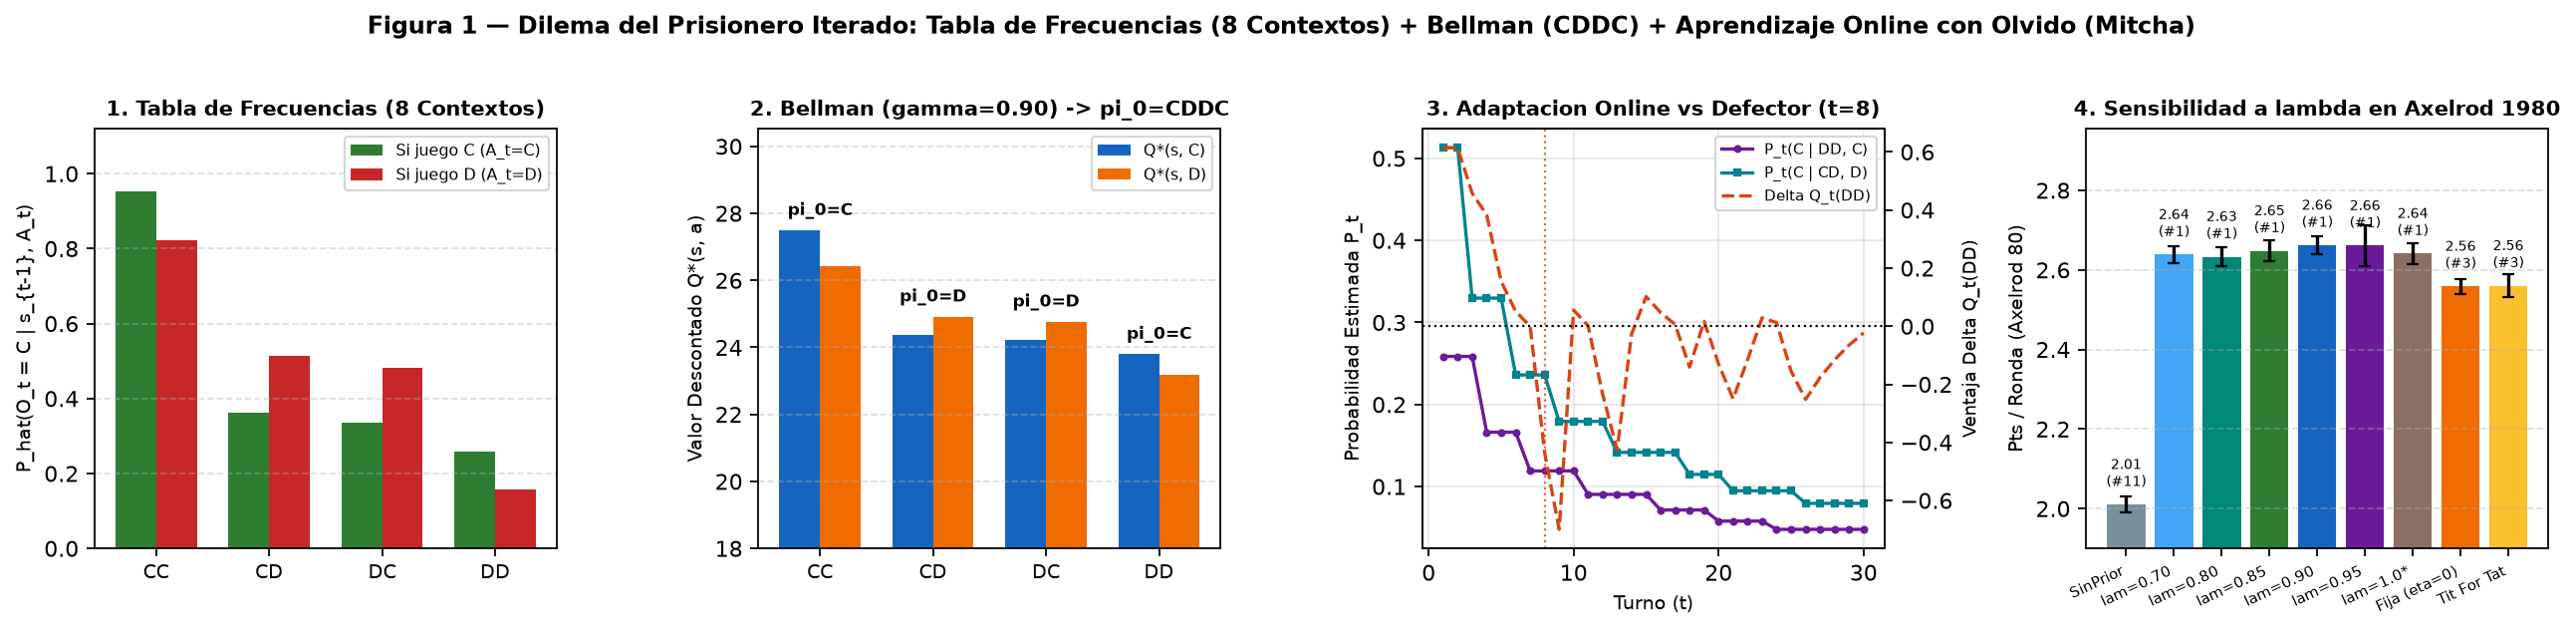

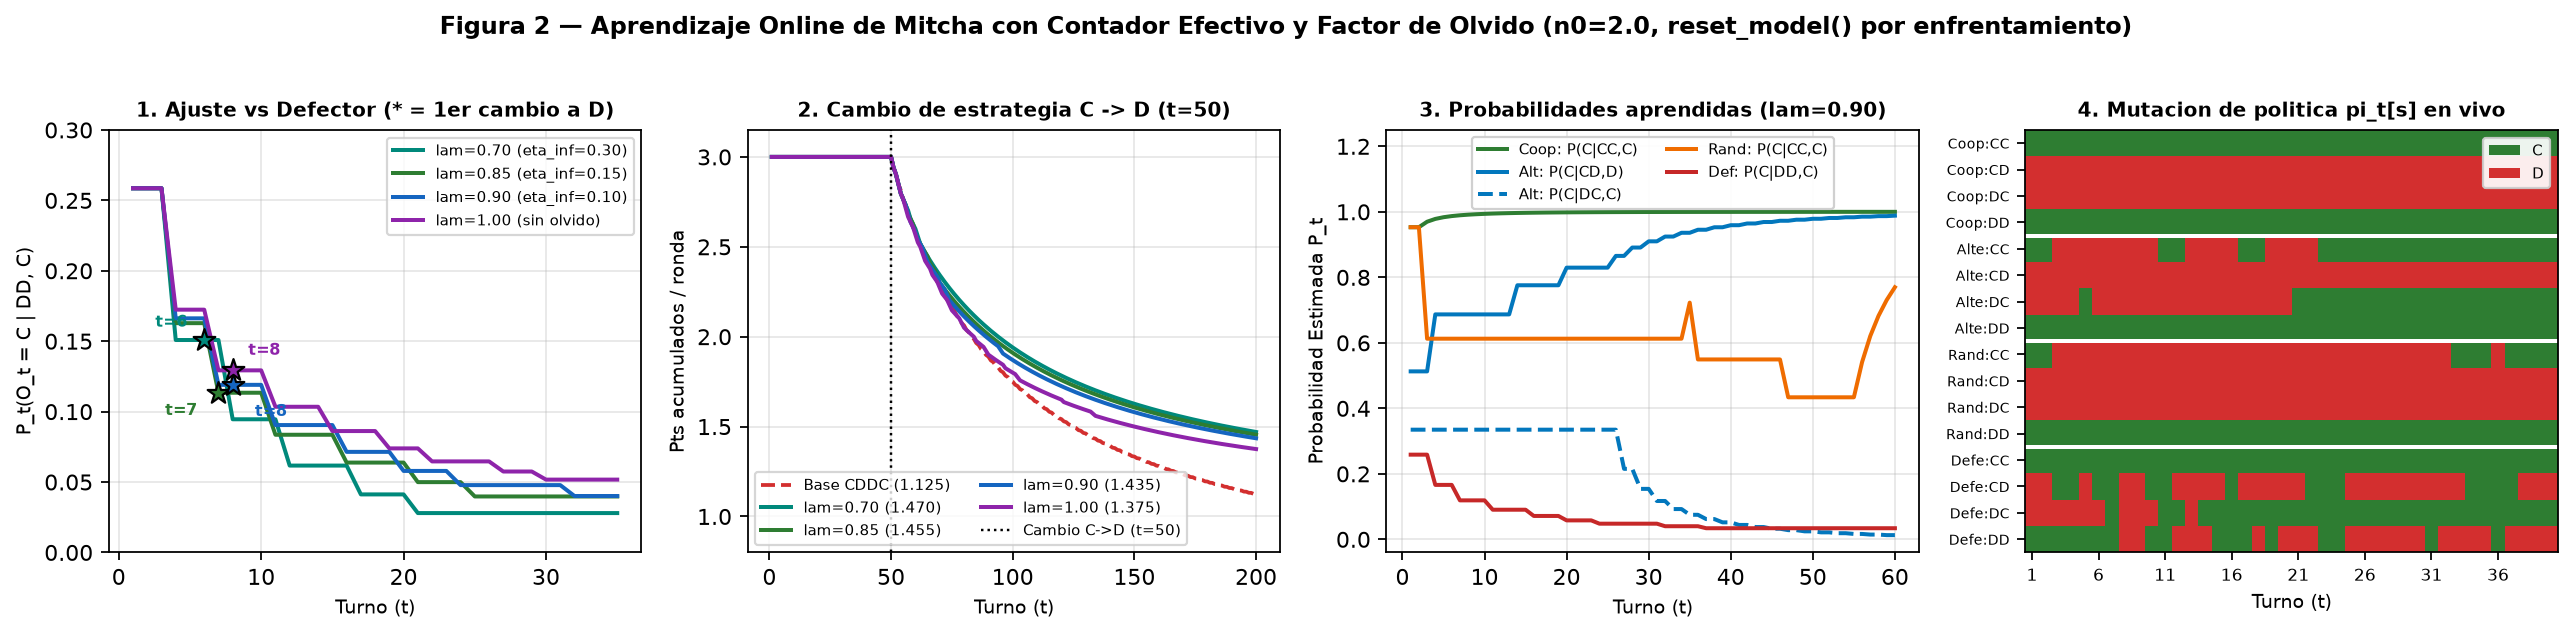

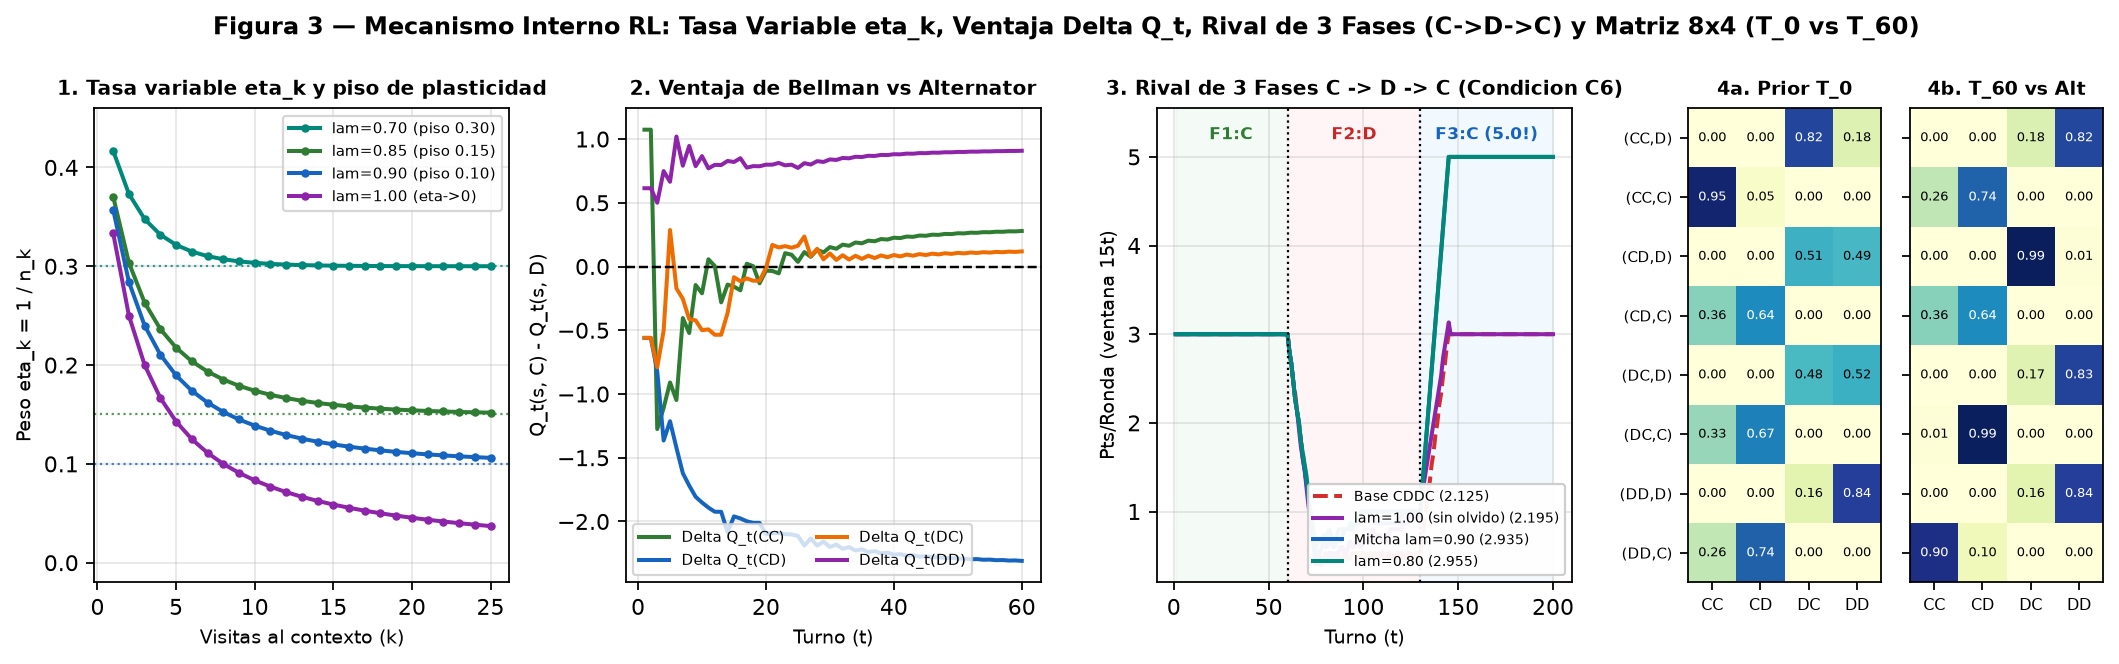

In [6]:
# --- FIGURA 1 ---
lambda_values = [0.70, 0.80, 0.85, 0.90, 0.95, 1.0]
lambda_rows = {}
standings_default = None
for lam in lambda_values:
    ag_lam = ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=lam, player_name=f"lam={lam}")
    st = evaluate_in_axelrod_1980(ag_lam, turns=200, repetitions=5, seed=42)
    lambda_rows[lam] = next(r for r in st if r["name"] == ag_lam.name)
    if lam == 0.90:
        standings_default = st

ag_stage1 = EmpiricalPolicyAgent(policy=bellman0.policy, player_name="Fija")
ag_no_prior = ForgettingTransitionRLAgent(prior_p=None, gamma=0.90, initial_count=2.0, forgetting_factor=0.90, player_name="SinPrior")
row_stage1 = next(r for r in evaluate_in_axelrod_1980(ag_stage1, 200, 5, 42) if r["name"] == "Fija")
row_no_prior = next(r for r in evaluate_in_axelrod_1980(ag_no_prior, 200, 5, 42) if r["name"] == "SinPrior")
row_tft = next(r for r in standings_default if r["name"] == "Tit For Tat")

comparison_scores = {
    "SinPrior": (row_no_prior["mean_norm"], row_no_prior["std_norm"], row_no_prior["rank"]),
    **{(f"lam={lam:.2f}" if lam < 1.0 else "lam=1.0*"): (lambda_rows[lam]["mean_norm"], lambda_rows[lam]["std_norm"], lambda_rows[lam]["rank"]) for lam in lambda_values},
    "Fija (eta=0)": (row_stage1["mean_norm"], row_stage1["std_norm"], row_stage1["rank"]),
    "Tit For Tat": (row_tft["mean_norm"], row_tft["std_norm"], row_tft["rank"]),
}
print(f"Sensibilidad SinPrior (0.50 uniforme) en Axelrod 1980 (5 reps): #{row_no_prior['rank']}/16 | {row_no_prior['mean_norm']:.3f} +- {row_no_prior['std_norm']:.3f}")

fig1, axes1 = plt.subplots(1, 4, figsize=(16.2, 3.85))
fig1.suptitle("Figura 1 — Dilema del Prisionero Iterado: Tabla de Frecuencias (8 Contextos) + Bellman (CDDC) + Aprendizaje Online con Olvido (Mitcha)", fontsize=11.0, fontweight="bold", y=1.02)
ax = axes1[0]; x = np.arange(len(STATES)); width = 0.36
ax.bar(x - width / 2, [freq.p_coop[(s, ACTION_C)] for s in range(4)], width, label="Si juego C (A_t=C)", color="#2e7d32")
ax.bar(x + width / 2, [freq.p_coop[(s, ACTION_D)] for s in range(4)], width, label="Si juego D (A_t=D)", color="#c62828")
ax.set_xticks(x); ax.set_xticklabels(STATES, fontsize=8.5); ax.set_ylim(0.0, 1.12); ax.set_ylabel("P_hat(O_t = C | s_{t-1}, A_t)", fontsize=8.5)
ax.set_title("1. Tabla de Frecuencias (8 Contextos)", fontsize=9.3, fontweight="bold"); ax.legend(fontsize=7.3, loc="upper right"); ax.grid(axis="y", linestyle="--", alpha=0.4)

ax = axes1[1]; q_c = [bellman0.q_values[(s, ACTION_C)] for s in range(4)]; q_d = [bellman0.q_values[(s, ACTION_D)] for s in range(4)]
ax.bar(x - width / 2, q_c, width, label="Q*(s, C)", color="#1565c0"); ax.bar(x + width / 2, q_d, width, label="Q*(s, D)", color="#ef6c00")
for s in range(4): ax.text(s, max(q_c[s], q_d[s]) + 0.45, f"pi_0={ACTION_LABELS[bellman0.policy[s]]}", ha="center", fontsize=7.8, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(STATES, fontsize=8.5); ax.set_ylim(18.0, max(q_c + q_d) * 1.11); ax.set_ylabel("Valor Descontado Q*(s, a)", fontsize=8.5)
ax.set_title("2. Bellman (gamma=0.90) -> pi_0=CDDC", fontsize=9.3, fontweight="bold"); ax.legend(fontsize=7.3, loc="upper right"); ax.grid(axis="y", linestyle="--", alpha=0.4)

ax = axes1[2]; turns_arr = np.arange(1, len(p_dd_c_hist) + 1)
ax.plot(turns_arr, p_dd_c_hist, label="P_t(C | DD, C)", color="#6a1b9a", marker="o", ms=2.6); ax.plot(turns_arr, p_cd_d_hist, label="P_t(C | CD, D)", color="#00838f", marker="s", ms=2.6)
ax2 = ax.twinx(); ax2.plot(turns_arr, delta_q_dd_hist, label="Delta Q_t(DD)", color="#d84315", linestyle="--"); ax2.axhline(0.0, color="black", linestyle=":", linewidth=1)
switch_t = next((i + 1 for i, snap in enumerate(mitcha_trace.trace_log) if snap["policy"][3] == ACTION_D), 8)
ax.axvline(switch_t, color="#d84315", linestyle=":", linewidth=1.0, alpha=0.8); ax.set_xlabel("Turno (t)", fontsize=8.5); ax.set_ylabel("Probabilidad Estimada P_t", fontsize=8.5); ax2.set_ylabel("Ventaja Delta Q_t(DD)", fontsize=8.2)
ax.set_title(f"3. Adaptacion Online vs Defector (t={switch_t})", fontsize=9.3, fontweight="bold"); l1, lb1 = ax.get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels()
ax.legend(l1 + l2, lb1 + lb2, fontsize=6.9, loc="upper right"); ax.grid(alpha=0.3)

ax = axes1[3]; labels_c = list(comparison_scores.keys()); means_c = [comparison_scores[k][0] for k in labels_c]; stds_c = [comparison_scores[k][1] for k in labels_c]; ranks_c = [comparison_scores[k][2] for k in labels_c]
colors_c = ["#78909c", "#42a5f5", "#00897b", "#2e7d32", "#1565c0", "#6a1b9a", "#8d6e63", "#ef6c00", "#fbc02d"]
bars = ax.bar(range(len(labels_c)), means_c, yerr=stds_c, capsize=2.5, color=colors_c[:len(labels_c)])
ax.set_xticks(range(len(labels_c))); ax.set_xticklabels(labels_c, fontsize=6.8, rotation=25, ha="right"); ax.set_ylim(1.90, max(means_c) * 1.11); ax.set_ylabel("Pts / Ronda (Axelrod 80)", fontsize=8.5)
ax.set_title("4. Sensibilidad a lambda en Axelrod 1980", fontsize=9.3, fontweight="bold")
for bar, mean, rank in zip(bars, means_c, ranks_c): ax.text(bar.get_x() + bar.get_width() / 2, mean + 0.035, f"{mean:.2f}\n(#{rank})", ha="center", va="bottom", fontsize=6.2)
ax.grid(axis="y", linestyle="--", alpha=0.4); plt.tight_layout(); fig1.savefig("resultados_experimento.png", dpi=160, bbox_inches="tight"); plt.show()

# --- FIGURA 2 ---
lambda_compare = [0.70, 0.85, 0.90, 1.0]; lam_colors = {0.70: "#00897b", 0.85: "#2e7d32", 0.90: "#1565c0", 1.0: "#8e24aa"}
defector_runs, switch_runs = {}, {}
for lam in lambda_compare:
    ag_d = ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=lam, record_trace=True)
    op_d = axl.Defector(); axl.Match((ag_d, op_d), turns=200, seed=42).play(); defector_runs[lam] = (ag_d, compute_cumulative_avg_scores(ag_d.history, op_d.history))
    ag_s = ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=lam, record_trace=True)
    op_s = CooperateThenDefect(50); axl.Match((ag_s, op_s), turns=200, seed=42).play(); switch_runs[lam] = (ag_s, compute_cumulative_avg_scores(ag_s.history, op_s.history))
fixed_ag = EmpiricalPolicyAgent(policy=bellman0.policy); fixed_op = CooperateThenDefect(50); axl.Match((fixed_ag, fixed_op), turns=200, seed=42).play()
fixed_switch_scores = compute_cumulative_avg_scores(fixed_ag.history, fixed_op.history)
rivals = [("Cooperator", axl.Cooperator()), ("Alternator", axl.Alternator()), ("Random", axl.Random()), ("Defector", axl.Defector())]
rival_runs = {}
for label, opp in rivals:
    ag_r = ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=0.90, record_trace=True)
    op_r = opp.clone(); axl.Match((ag_r, op_r), turns=60, seed=42).play(); rival_runs[label] = (ag_r, op_r, compute_cumulative_avg_scores(ag_r.history, op_r.history))

fig2, axes2 = plt.subplots(1, 4, figsize=(16.2, 3.85))
fig2.suptitle("Figura 2 — Aprendizaje Online de Mitcha con Contador Efectivo y Factor de Olvido (n0=2.0, reset_model() por enfrentamiento)", fontsize=11.0, fontweight="bold", y=1.02)
ax = axes2[0]; t35 = np.arange(1, 36); ann_offsets = {0.70: (-22, 6), 0.85: (-24, -10), 0.90: (10, -14), 1.0: (7, 7)}
for lam in lambda_compare:
    ag_d, _ = defector_runs[lam]; p_dd_c = [snap["probs"][(3, ACTION_C)] for snap in ag_d.trace_log[:35]]; pol_dd = [snap["policy"][3] for snap in ag_d.trace_log[:35]]
    ax.plot(t35, p_dd_c, label=f"lam={lam:.2f}" + (" (sin olvido)" if lam == 1.0 else f" (eta_inf={1-lam:.2f})"), color=lam_colors[lam], linewidth=1.8)
    first_d = next((idx for idx, act in enumerate(pol_dd) if act == ACTION_D), None)
    if first_d is not None:
        ax.scatter(t35[first_d], p_dd_c[first_d], color=lam_colors[lam], marker="*", s=105, zorder=5, edgecolor="black")
        ax.annotate(f"t={t35[first_d]}", (t35[first_d], p_dd_c[first_d]), textcoords="offset points", xytext=ann_offsets[lam], fontsize=7.3, color=lam_colors[lam], fontweight="bold")
ax.set_xlabel("Turno (t)", fontsize=8.5); ax.set_ylabel("P_t(O_t = C | DD, C)", fontsize=8.5); ax.set_title("1. Ajuste vs Defector (* = 1er cambio a D)", fontsize=9.2, fontweight="bold")
ax.set_ylim(0.0, 0.30); ax.legend(fontsize=6.9, loc="upper right"); ax.grid(alpha=0.3)

ax = axes2[1]; t200 = np.arange(1, 201)
ax.plot(t200, fixed_switch_scores, label=f"Base CDDC ({fixed_switch_scores[-1]:.3f})", color="#d32f2f", linestyle="--", linewidth=1.7)
for lam in lambda_compare: ax.plot(t200, switch_runs[lam][1], label=f"lam={lam:.2f} ({switch_runs[lam][1][-1]:.3f})", color=lam_colors[lam], linewidth=1.8)
ax.axvline(50, color="black", linestyle=":", linewidth=1.1, label="Cambio C->D (t=50)"); ax.set_xlabel("Turno (t)", fontsize=8.5); ax.set_ylabel("Pts acumulados / ronda", fontsize=8.5)
ax.set_title("2. Cambio de estrategia C -> D (t=50)", fontsize=9.2, fontweight="bold"); ax.set_ylim(0.8, 3.15); ax.legend(fontsize=6.8, loc="lower left", ncol=2); ax.grid(alpha=0.3)

ax = axes2[2]; t60 = np.arange(1, 61)
curves = [("Coop: P(C|CC,C)", "Cooperator", (0, ACTION_C), "#2e7d32", "-"), ("Alt: P(C|CD,D)", "Alternator", (1, ACTION_D), "#0277bd", "-"), ("Alt: P(C|DC,C)", "Alternator", (2, ACTION_C), "#0277bd", "--"), ("Rand: P(C|CC,C)", "Random", (0, ACTION_C), "#ef6c00", "-"), ("Def: P(C|DD,C)", "Defector", (3, ACTION_C), "#c62828", "-")]
for label, rival_key, ctx, color, ls in curves: ax.plot(t60, [snap["probs"][ctx] for snap in rival_runs[rival_key][0].trace_log[:60]], label=label, color=color, linestyle=ls, linewidth=1.8)
ax.set_xlabel("Turno (t)", fontsize=8.5); ax.set_ylabel("Probabilidad Estimada P_t", fontsize=8.5); ax.set_title("3. Probabilidades aprendidas (lam=0.90)", fontsize=9.2, fontweight="bold")
ax.set_ylim(-0.04, 1.25); ax.legend(fontsize=6.6, loc="upper center", ncol=2, framealpha=0.92); ax.grid(alpha=0.3)

ax = axes2[3]; turns_map = 40; grid_rows, y_labels = [], []
for rival_name, _ in rivals:
    for s_idx, s_name in enumerate(STATES):
        grid_rows.append([rival_runs[rival_name][0].trace_log[t]["policy"][s_idx] for t in range(turns_map)]); y_labels.append(f"{rival_name[:4]}:{s_name}")
ax.imshow(np.array(grid_rows), aspect="auto", cmap=ListedColormap(["#d32f2f", "#2e7d32"]), vmin=0, vmax=1, interpolation="nearest")
for sep in (3.5, 7.5, 11.5): ax.axhline(sep, color="white", linewidth=1.8)
ax.set_yticks(range(len(y_labels))); ax.set_yticklabels(y_labels, fontsize=6.4); ax.set_xticks(np.arange(0, turns_map, 5)); ax.set_xticklabels(np.arange(1, turns_map + 1, 5), fontsize=7.5)
ax.set_xlabel("Turno (t)", fontsize=8.5); ax.set_title("4. Mutacion de politica pi_t[s] en vivo", fontsize=9.2, fontweight="bold")
ax.legend(handles=[Patch(facecolor="#2e7d32", label="C"), Patch(facecolor="#d32f2f", label="D")], loc="upper right", fontsize=6.9, framealpha=0.92)
plt.tight_layout(); fig2.savefig("aprendizaje_olvido.png", dpi=160, bbox_inches="tight"); plt.show()

# --- FIGURA 3 ---
def rolling_round_scores(my_history, opp_history, window=15):
    round_pts = [PAYOFF[(ACTION_C if a == C else ACTION_D, ACTION_C if o == C else ACTION_D)] for a, o in zip(my_history, opp_history)]
    return [sum(round_pts[max(0, i - window + 1):i + 1]) / len(round_pts[max(0, i - window + 1):i + 1]) for i in range(len(round_pts))]

fig3 = plt.figure(figsize=(16.2, 3.85)); gs = fig3.add_gridspec(1, 4, wspace=0.28)
fig3.suptitle("Figura 3 — Mecanismo Interno RL: Tasa Variable eta_k, Ventaja Delta Q_t, Rival de 3 Fases (C->D->C) y Matriz 8x4 (T_0 vs T_60)", fontsize=11.0, fontweight="bold", y=1.03)
ax1 = fig3.add_subplot(gs[0, 0]); visits = np.arange(1, 26)
for lam, col, lbl in [(0.70, "#00897b", "lam=0.70 (piso 0.30)"), (0.85, "#2e7d32", "lam=0.85 (piso 0.15)"), (0.90, "#1565c0", "lam=0.90 (piso 0.10)"), (1.00, "#8e24aa", "lam=1.00 (eta->0)")]:
    n_val = 2.0; etas = []
    for _ in visits: n_val = lam * n_val + 1.0; etas.append(1.0 / n_val)
    ax1.plot(visits, etas, marker="o", ms=2.8, color=col, linewidth=1.8, label=lbl)
    if lam < 1.0: ax1.axhline(1.0 - lam, color=col, linestyle=":", linewidth=1.0, alpha=0.8)
ax1.set_xlabel("Visitas al contexto (k)", fontsize=8.5); ax1.set_ylabel("Peso eta_k = 1 / n_k", fontsize=8.5); ax1.set_title("1. Tasa variable eta_k y piso de plasticidad", fontsize=9.0, fontweight="bold")
ax1.set_ylim(-0.02, 0.46); ax1.legend(fontsize=6.8, loc="upper right"); ax1.grid(alpha=0.3)

ax2 = fig3.add_subplot(gs[0, 1]); alt_agent = rival_runs["Alternator"][0]
for s_idx, (s_name, col) in enumerate(zip(STATES, ["#2e7d32", "#1565c0", "#ef6c00", "#8e24aa"])): ax2.plot(t60, [snap["delta_q"][s_idx] for snap in alt_agent.trace_log[:60]], label=f"Delta Q_t({s_name})", color=col, linewidth=1.8)
ax2.axhline(0.0, color="black", linestyle="--", linewidth=1.1); ax2.set_xlabel("Turno (t)", fontsize=8.5); ax2.set_ylabel("Q_t(s, C) - Q_t(s, D)", fontsize=8.5)
ax2.set_title("2. Ventaja de Bellman vs Alternator", fontsize=9.0, fontweight="bold"); ax2.legend(fontsize=6.8, loc="lower left", ncol=2); ax2.grid(alpha=0.3)

ax3 = fig3.add_subplot(gs[0, 2])
for lbl, col, ls, ag_p in [("Base CDDC", "#d32f2f", "--", EmpiricalPolicyAgent(policy=bellman0.policy)), ("lam=1.00 (sin olvido)", "#8e24aa", "-", ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=1.0)), ("Mitcha lam=0.90", "#1565c0", "-", ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=0.90)), ("lam=0.80", "#00897b", "-", ForgettingTransitionRLAgent(prior_p=freq.p_coop, gamma=0.90, initial_count=2.0, forgetting_factor=0.80))]:
    op_p = ThreePhaseRival(); axl.Match((ag_p, op_p), turns=200, seed=42).play()
    ax3.plot(t200, rolling_round_scores(ag_p.history, op_p.history, 15), label=f"{lbl} ({compute_cumulative_avg_scores(ag_p.history, op_p.history)[-1]:.3f})", color=col, linestyle=ls, linewidth=1.8)
ax3.axvspan(1, 60, color="#e8f5e9", alpha=0.45); ax3.axvspan(60, 130, color="#ffebee", alpha=0.45); ax3.axvspan(130, 200, color="#e3f2fd", alpha=0.45)
ax3.axvline(60, color="black", linestyle=":", linewidth=1.0); ax3.axvline(130, color="black", linestyle=":", linewidth=1.0)
ax3.text(30, 5.2, "F1:C", ha="center", fontsize=7.5, fontweight="bold", color="#2e7d32"); ax3.text(95, 5.2, "F2:D", ha="center", fontsize=7.5, fontweight="bold", color="#c62828"); ax3.text(165, 5.2, "F3:C (5.0!)", ha="center", fontsize=7.5, fontweight="bold", color="#1565c0")
ax3.set_xlabel("Turno (t)", fontsize=8.5); ax3.set_ylabel("Pts/Ronda (ventana 15t)", fontsize=8.5); ax3.set_title("3. Rival de 3 Fases C -> D -> C (Condicion C6)", fontsize=9.0, fontweight="bold")
ax3.set_ylim(0.2, 5.55); ax3.legend(fontsize=6.5, loc="lower right", framealpha=0.95); ax3.grid(alpha=0.3)

sub_gs = gs[0, 3].subgridspec(1, 2, wspace=0.15); base_mat = build_mdp_transition_matrix(freq.p_coop); learned_mat = alt_agent.mdp_transitions
ctx_keys = [(s, a) for s in range(4) for a in ACTIONS]; ctx_labels = [f"({STATES[s]},{ACTION_LABELS[a]})" for s, a in ctx_keys]
mat_b = np.array([[base_mat[k][sn] for sn in range(4)] for k in ctx_keys]); mat_a = np.array([[learned_mat[k][sn] for sn in range(4)] for k in ctx_keys])
for c_idx, (mat, stitle) in enumerate([(mat_b, "4a. Prior T_0"), (mat_a, "4b. T_60 vs Alt")]):
    ax_m = fig3.add_subplot(sub_gs[0, c_idx]); ax_m.imshow(mat, cmap="YlGnBu", vmin=0.0, vmax=1.0, aspect="auto")
    ax_m.set_xticks(range(4)); ax_m.set_xticklabels(STATES, fontsize=7.0); ax_m.set_yticks(range(len(ctx_labels))); ax_m.set_yticklabels(ctx_labels if c_idx == 0 else [], fontsize=6.8); ax_m.set_title(stitle, fontsize=8.6, fontweight="bold")
    for r_i in range(mat.shape[0]):
        for c_i in range(mat.shape[1]):
            val = mat[r_i, c_i]; ax_m.text(c_i, r_i, f"{val:.2f}", ha="center", va="center", fontsize=6.0, color="white" if val > 0.55 else "black")
fig3.savefig("aprendizaje_detalle_rl.png", dpi=160, bbox_inches="tight"); plt.show()

## 8. Suite de Pruebas Unitarias Integradas (`unittest`)

In [7]:
class TestTaller5MdpAndAgents(unittest.TestCase):
    def test_frequency_table_exact_counts_and_mdp_rows(self) -> None:
        small_pool = [axl.Cooperator(), axl.Defector(), axl.TitForTat(), axl.Alternator()]
        ft = collect_frequency_table(small_pool, turns=20, repetitions=1, seed=42)
        self.assertEqual(ft.total_transitions, sum(ft.counts_total.values()))
        self.assertEqual(len(ft.p_coop), 8)
        for (_, action), row in ft.mdp_transitions.items():
            self.assertAlmostEqual(sum(row.values()), 1.0, places=12)
            self.assertEqual((row[2], row[3]) if action == ACTION_C else (row[0], row[1]), (0.0, 0.0))

    def test_bellman_optimality_and_cddc_emergence(self) -> None:
        res = solve_bellman(freq.p_coop, gamma=0.90, tol=1e-6, max_iter=2000)
        self.assertGreater(res.iterations, 0)
        self.assertLess(res.iterations, 2000)
        for s in range(4):
            self.assertLessEqual(abs(res.v_values[s] - max(res.q_values[(s, ACTION_C)], res.q_values[(s, ACTION_D)])), 1e-6)
        self.assertEqual("".join(ACTION_LABELS[a] for a in res.policy), "CDDC")

    def test_mitcha_effective_counts_matrix_invariants_and_match_reset(self) -> None:
        custom_prior = {(s, a): 0.75 for s in range(4) for a in ACTIONS}
        ag = ForgettingTransitionRLAgent(prior_p=custom_prior, gamma=0.90, initial_count=2.0, forgetting_factor=0.90, record_trace=True)
        axl.Match((ag, axl.Defector()), turns=12).play()
        self.assertLess(ag.effective_counts[(3, ACTION_D)], 1.0 / (1.0 - 0.90))
        ag.reset()
        self.assertEqual(ag.strategy(axl.Cooperator()), C)
        self.assertAlmostEqual(ag.effective_counts[(3, ACTION_C)], 2.0, places=12)

    def test_mitcha_adapts_faster_with_forgetting_after_regime_switch(self) -> None:
        prior = {(s, a): 0.80 for s in range(4) for a in ACTIONS}
        no_f = ForgettingTransitionRLAgent(prior_p=prior, initial_count=1.0, forgetting_factor=1.0)
        with_f = ForgettingTransitionRLAgent(prior_p=prior, initial_count=1.0, forgetting_factor=0.80)
        axl.Match((no_f, CooperateThenDefect(50)), turns=100).play()
        axl.Match((with_f, CooperateThenDefect(50)), turns=100).play()
        self.assertGreater(sum(1 for m in with_f.history[50:] if m == D), sum(1 for m in no_f.history[50:] if m == D))

suite = unittest.TestLoader().loadTestsFromTestCase(TestTaller5MdpAndAgents)
unittest.TextTestRunner(verbosity=2).run(suite)
print(f"\nTiempo total de ejecucion completa del notebook: {time.time() - t_nb_start:.1f}s")

test_bellman_optimality_and_cddc_emergence (__main__.TestTaller5MdpAndAgents.test_bellman_optimality_and_cddc_emergence) ... ok
test_frequency_table_exact_counts_and_mdp_rows (__main__.TestTaller5MdpAndAgents.test_frequency_table_exact_counts_and_mdp_rows) ... ok
test_mitcha_adapts_faster_with_forgetting_after_regime_switch (__main__.TestTaller5MdpAndAgents.test_mitcha_adapts_faster_with_forgetting_after_regime_switch) ... ok
test_mitcha_effective_counts_matrix_invariants_and_match_reset (__main__.TestTaller5MdpAndAgents.test_mitcha_effective_counts_matrix_invariants_and_match_reset) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.034s

OK

Tiempo total de ejecucion completa del notebook: 193.2s
